# Classification and Its Fork: From Regression to Categories
Dataset: **Breast Cancer Wisconsin (Diagnostic) Dataset**

Predict whether a tumour is **Malignant (1)** or **Benign (0)**

In [3]:
# Setup: Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score, log_loss, classification_report
)

# Set visual style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!



## Problem with Regression

In regression, we predict a continuous number (like house price or temperature). Now, our goal is to predict a **category**:
* Is a tumour **malignant** (`1`) or **benign** (`0`)?
* Is an email **spam** (`1`) or **not spam** (`0`)?

If we fit a standard **Linear Regression** line to a binary `0` or `1` target, it outputs arbitrary numbers, including values less than `0` (like `-0.4`) or greater than `1` (like `1.6`), which make no sense as category probabilities.

In [4]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)

# In sklearn's dataset, 0 = malignant, 1 = benign. 
# Let's flip it so 1 = Malignant (Positive class) and 0 = Benign (Negative class), matching medical intuition!
df['is_malignant'] = (data.target == 0).astype(int)

print(f"Dataset shape: {df.shape[0]} patients, {df.shape[1]-1} tumour measurements")
print(f"Class counts:\n{df['is_malignant'].value_counts().rename({1: 'Malignant (1)', 0: 'Benign (0)'})}")
df[['mean radius', 'mean texture', 'mean area', 'is_malignant']].head()

Dataset shape: 569 patients, 30 tumour measurements
Class counts:
is_malignant
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64


,mean radius,mean texture,mean area,is_malignant
0,17.99,10.38,1001.0,1
1,20.57,17.77,1326.0,1
2,19.69,21.25,1203.0,1
3,11.42,20.38,386.1,1
4,20.29,14.34,1297.0,1


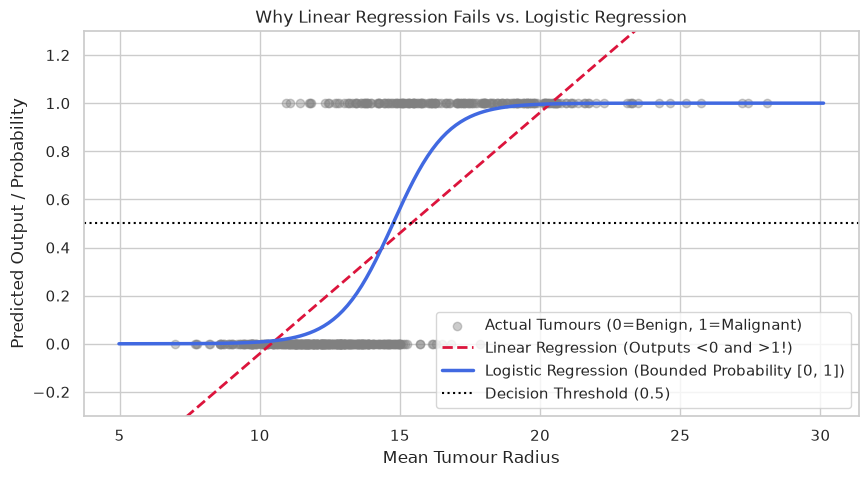

In [5]:
# Visualize why Linear Regression fails for Classification
X_single = df[['mean radius']].values
y = df['is_malignant'].values

lin_reg = LinearRegression().fit(X_single, y)
log_reg = LogisticRegression().fit(X_single, y)

x_range = np.linspace(df['mean radius'].min() - 2, df['mean radius'].max() + 2, 300).reshape(-1, 1)

plt.figure(figsize=(10, 5))
plt.scatter(X_single, y, alpha=0.4, color='gray', label='Actual Tumours (0=Benign, 1=Malignant)')
plt.plot(x_range, lin_reg.predict(x_range), color='crimson', linestyle='--', linewidth=2, label='Linear Regression (Outputs <0 and >1!)')
plt.plot(x_range, log_reg.predict_proba(x_range)[:, 1], color='royalblue', linewidth=2.5, label='Logistic Regression (Bounded Probability [0, 1])')
plt.axhline(0.5, color='black', linestyle=':', label='Decision Threshold (0.5)')
plt.ylim(-0.3, 1.3)
plt.xlabel('Mean Tumour Radius')
plt.ylabel('Predicted Output / Probability')
plt.title('Why Linear Regression Fails vs. Logistic Regression')
plt.legend()
plt.show()

## Binary vs. Multi-Class & The Confusion Matrix

* **Binary Classification:** Two categories (e.g., Malignant vs. Benign, Spam vs. Not Spam).
* **Multi-Class Classification:** More than two categories (e.g., classifying emails into *Primary*, *Social*, *Promotions*, or *Spam*).

### Why Accuracy Alone Can Mislead
Suppose 98% of emails are legitimate and only 2% are spam. A lazy model that predicts **"Not Spam" for every single email** achieves **98% accuracy**, yet it catches **0% of the spam**!

To see the full picture, we use a **Confusion Matrix**, which records four counts for a binary problem:
1. **True Positives (TP):** Actually Positive, predicted Positive *(Model was right)*
2. **True Negatives (TN):** Actually Negative, predicted Negative *(Model was right)*
3. **False Positives (FP):** Actually Negative, predicted Positive *(False alarm - Model was wrong)*
4. **False Negatives (FN):** Actually Positive, predicted Negative *(Missed detection - Model was wrong)*

From these four counts come two vital metrics:
$$\text{Precision} = \frac{TP}{TP + FP} \quad \text{(Share of positive predictions that were correct)}$$

$$\text{Recall} = \frac{TP}{TP + FN} \quad \text{(Share of real positives that were found)}$$

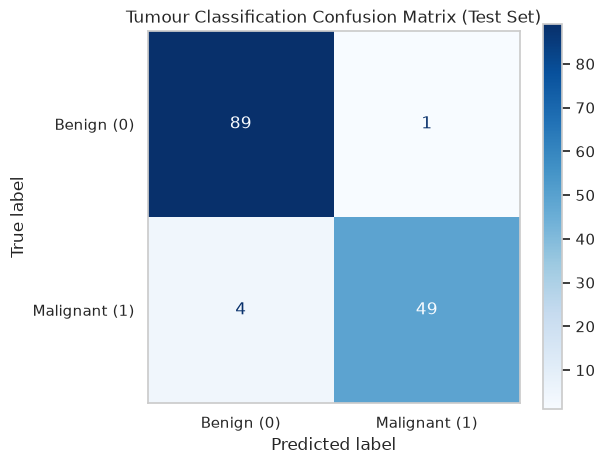

True Positives (TP):  49 (Malignant correctly caught)
True Negatives (TN):  89 (Benign correctly cleared)
False Positives (FP): 1 (Benign falsely flagged as malignant)
False Negatives (FN): 4 (Malignant missed!)
---------------------------------------------
Accuracy:  0.9650
Precision: 0.9800  -> 49 / (49 + 1)
Recall:    0.9245  -> 49 / (49 + 4)


In [6]:
# Train a real Logistic Regression classifier on all 30 tumour features
X = df.drop(columns=['is_malignant'])
y = df['is_malignant']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Predict classes (default threshold = 0.5) and probabilities
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign (0)', 'Malignant (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Tumour Classification Confusion Matrix (Test Set)')
plt.grid(False)
plt.show()

print(f"True Positives (TP):  {tp} (Malignant correctly caught)")
print(f"True Negatives (TN):  {tn} (Benign correctly cleared)")
print(f"False Positives (FP): {fp} (Benign falsely flagged as malignant)")
print(f"False Negatives (FN): {fn} (Malignant missed!)")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}  -> {tp} / ({tp} + {fp})")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}  -> {tp} / ({tp} + {fn})")

## Worked Example: The Spam Filter Trade-Off

> *Consider a spam filter that flagged **110 messages**, of which **90 were truly spam** and **20 were not**, while failing to catch **30 real spam messages**.*

Let's map these numbers to our confusion matrix terms:
* **True Positives ($TP$):** `90` (flagged as spam, and truly spam)
* **False Positives ($FP$):** `20` (flagged as spam, but actually legitimate email)
* **False Negatives ($FN$):** `30` (real spam messages that slipped into the inbox)

In [7]:
# Worked Example: Spam Filter Calculation
tp_spam = 90
fp_spam = 20
fn_spam = 30

total_flagged = tp_spam + fp_spam       # 110 messages flagged
total_real_spam = tp_spam + fn_spam     # 120 real spam messages

precision_spam = tp_spam / (tp_spam + fp_spam)
recall_spam = tp_spam / (tp_spam + fn_spam)
f1_spam = 2 * (precision_spam * recall_spam) / (precision_spam + recall_spam)

print(f"Total Positives Predicted (Flagged): {total_flagged}")
print(f"Total Actual Positives (Real Spam):  {total_real_spam}")
print("-" * 40)
print(f"Precision = {tp_spam} / {total_flagged} = {precision_spam:.4f} (about 0.82)")
print(f"Recall    = {tp_spam} / {total_real_spam} = {recall_spam:.4f} (about 0.75)")
print(f"F1 Score  = {f1_spam:.4f}")

Total Positives Predicted (Flagged): 110
Total Actual Positives (Real Spam):  120
----------------------------------------
Precision = 90 / 110 = 0.8182 (about 0.82)
Recall    = 90 / 120 = 0.7500 (about 0.75)
F1 Score  = 0.7826


### The Core Trade-Off: Which Mistake Costs More?
Whether we tune a model for higher **Precision** or higher **Recall** depends on the real-world cost of each mistake:
* **Spam Filter (High Precision preferred):** A False Positive sends an important job offer or bank alert to the Spam folder. Users hate missing real emails more than seeing an occasional spam email in their inbox.
* **Cancer Screening (High Recall preferred):** A False Negative misses a malignant tumour, delaying life-saving treatment. Doctors prefer a few extra False Positives (follow-up tests) over missing a real cancer case.

### How to Improve & Evaluate: F1 Score, ROC-AUC, and Log Loss

To complete our evaluation toolkit beyond simple accuracy:

1. **F1 Score:** The harmonic mean of Precision and Recall. It balances both into a single number when both false positives and false negatives matter:
   $$F_1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$
2. **ROC Curve & AUC:** The **Receiver Operating Characteristic (ROC)** curve plots the **True Positive Rate (Recall)** against the **False Positive Rate** as we slide the classification threshold from `1.0` down to `0.0`. The **Area Under the Curve (AUC)** summarizes how well the model separates the two classes across *every* possible threshold (`1.0` = perfect separator, `0.5` = random coin flip).
3. **Log Loss (Cross-Entropy Loss):** Evaluates the *predicted probabilities* directly rather than hard `0/1` class labels. It heavily penalizes confident wrong predictions and rewards confident, correct probabilities.

F1 Score: 0.9515
ROC-AUC:  0.9962
Log Loss: 0.0776 (Lower is better; 0.0 is perfection)


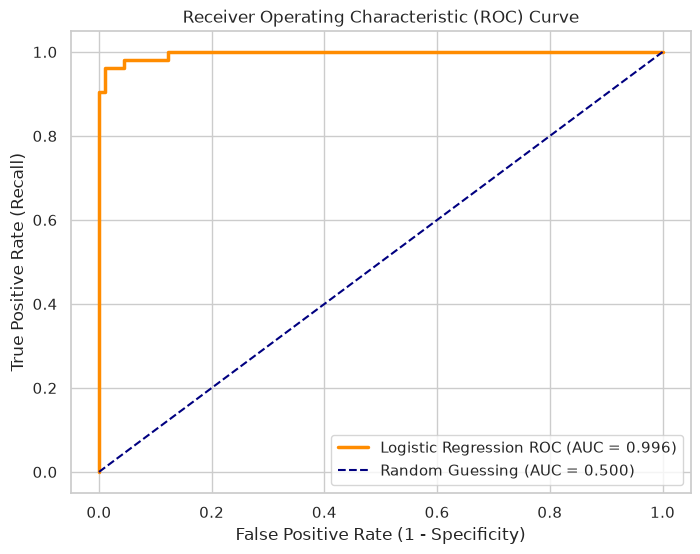

In [8]:
# Calculate F1 Score, ROC-AUC, and Log Loss on our Tumour Classifier
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
loss = log_loss(y_test, y_prob)

print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC:  {roc_auc:.4f}")
print(f"Log Loss: {loss:.4f} (Lower is better; 0.0 is perfection)")

# Plot the ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Logistic Regression ROC (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

## Where This Leads: Probabilities + Thresholds

Every classification algorithm must turn input features into a predicted class. 
The closest bridge from regression to classification is **Logistic Regression**:
1. First, it computes a weighted sum of features (just like linear regression).
2. Next, it passes that number through the **sigmoid function** to squash it into a probability between `0` and `1`.
3. Finally, it applies a **decision threshold** (commonly `0.5`, though we can lower it to `0.2` to boost Recall in cancer detection, or raise it to `0.8` to boost Precision in spam filtering).

Move the threshold of our tumor model

In [9]:
# Experiment: How moving the threshold changes Precision, Recall, and F1
custom_thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]
results = []

for thresh in custom_thresholds:
    preds_at_thresh = (y_prob >= thresh).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, preds_at_thresh).ravel()
    results.append({
        'Threshold': thresh,
        'TP (Caught)': tp_t,
        'FP (False Alarm)': fp_t,
        'FN (Missed)': fn_t,
        'Precision': round(precision_score(y_test, preds_at_thresh), 4),
        'Recall': round(recall_score(y_test, preds_at_thresh), 4),
        'F1 Score': round(f1_score(y_test, preds_at_thresh), 4)
    })

thresh_df = pd.DataFrame(results)
print("Effect of Changing the Decision Threshold on Tumour Predictions:")
display(thresh_df)

Effect of Changing the Decision Threshold on Tumour Predictions:


,Threshold,TP (Caught),FP (False Alarm),FN (Missed),Precision,Recall,F1 Score
0,0.1,52,6,1,0.8966,0.9811,0.9369
1,0.3,51,1,2,0.9808,0.9623,0.9714
2,0.5,49,1,4,0.9800,0.9245,0.9515
3,0.7,48,0,5,1.0000,0.9057,0.9505
4,0.9,43,0,10,1.0000,0.8113,0.8958


Test your understanding with the three key questions from the notes before running the verification cell below:

1. **Compute precision and recall for a filter with 110 total positives predicted, 90 correct, and 30 real positives missed.**
2. **Why is accuracy alone a poor measure on an unbalanced dataset?**
3. **What does the area under the ROC curve (ROC-AUC) summarise?**

---

   * **Precision:** $\frac{90}{110} \approx 0.818$ ($81.8\%$)
   * **Recall:** $\frac{90}{90 + 30} = \frac{90}{120} = 0.75$ ($75.0\%$)
   * When one class is rare (e.g., 1% fraud or 2% spam), a model can achieve 98%–99% accuracy simply by always predicting the majority class, completely failing to detect the minority class of interest.
   * It summarises how well the model distinguishes between the positive and negative classes across **all possible classification thresholds** (specifically, the probability that a randomly chosen positive instance is ranked higher than a randomly chosen negative instance).

In [ ]:
# Quick Python check demonstrating Question 2 (Unbalanced Dataset Illusion)
# Imagine 1,000 transactions where only 10 (1%) are fraudulent
y_unbalanced = np.array([1]*10 + [0]*990)
y_dummy_pred = np.zeros_like(y_unbalanced)  # Model predicts "Not Fraud" (0) every single time

print(f"Dummy Model Accuracy:  {accuracy_score(y_unbalanced, y_dummy_pred)*100:.1f}% (Looks great, but useless!)")
print(f"Dummy Model Recall:    {recall_score(y_unbalanced, y_dummy_pred)*100:.1f}% (Caught 0 out of 10 frauds)")
print(f"Dummy Model Precision: {precision_score(y_unbalanced, y_dummy_pred, zero_division=0)*100:.1f}%")